# Confidence interval vs number of simulations

The Monte Carlo standard error decreases as $1/\sqrt{N}$. We check this on the Longstaff-Schwartz American put, and compare the theoretical standard error with the empirical dispersion of the price across independant runs.

In [1]:
import sys
sys.path.append("..")

import numpy as np
import matplotlib.pyplot as plt

from src.analysis import convergence_study

S0, K, r, q, sigma, T = 100.0, 100.0, 0.05, 0.02, 0.20, 1.0
n_steps = 50
n_grid = [1_000, 2_500, 5_000, 10_000, 20_000, 40_000]

In [2]:
quick = convergence_study(S0, K, r, q, sigma, T, n_steps, [1_000], n_rep=2)
print(quick.round(4).to_string(index=False))

   N  rep  price  std_error  ci_low  ci_high
1000    0 7.2562     0.2590  6.7486   7.7638
1000    1 6.9211     0.2446  6.4417   7.4006


In [3]:
study = convergence_study(S0, K, r, q, sigma, T, n_steps, n_grid, n_rep=10)
summary = study.groupby("N").agg(
    mean_price=("price", "mean"),
    emp_std=("price", lambda x: x.std(ddof=1)),
    mean_se=("std_error", "mean"),
).reset_index()
summary["ci_width"] = 2 * 1.96 * summary["mean_se"]

print(summary.round(4).to_string(index=False))

    N  mean_price  emp_std  mean_se  ci_width
 1000      6.8800   0.3194   0.2509    0.9834
 2500      6.7112   0.1620   0.1534    0.6012
 5000      6.5931   0.0538   0.1077    0.4223
10000      6.6645   0.1092   0.0772    0.3027
20000      6.6587   0.0451   0.0548    0.2149
40000      6.6567   0.0470   0.0387    0.1516


## Rate of convergence and empirical coverage

1. Log-log fit of the standard error against N (expected slope: -1/2)
2. Coverage: Share of runs whose 95% CI contains the Bermudan tree price

In [5]:
slope_se, intercept_se = np.polyfit(np.log(study["N"]), np.log(study["std_error"]), 1)
print(f"Slope of log(std_error) vs log(N): {slope_se:.3f}   (theory: -0.500)")

emp = summary[summary["emp_std"] > 0]
slope_emp, _ = np.polyfit(np.log(emp["N"]), np.log(emp["emp_std"]), 1)
print(f"Slope of log(empirical std) vs log(N): {slope_emp:.3f}   (noisy: only 10 runs per N)")

Slope of log(std_error) vs log(N): -0.503   (theory: -0.500)
Slope of log(empirical std) vs log(N): -0.507   (noisy: only 10 runs per N)


In [6]:
from src.binomial import crr_price

ref = crr_price(S0, K, r, q, sigma, T, 1000, "put", american=True, exercise_every=20)
print(f"Reference (Bermudan tree): {ref:.4f}\n")

study["covers"] = (study["ci_low"] <= ref) & (ref <= study["ci_high"])
print(study.groupby("N")["covers"].mean().to_string())
print(f"\nOverall coverage: {study['covers'].mean():.1%} over {len(study)} runs")

Reference (Bermudan tree): 6.6517

N
1000     0.8
2500     0.9
5000     1.0
10000    0.9
20000    1.0
40000    0.9

Overall coverage: 91.7% over 60 runs


In [8]:
cov = convergence_study(S0, K, r, q, sigma, T, n_steps, [5_000], n_rep=50, base_seed=5000)
cov["covers"] = (cov["ci_low"] <= ref) & (ref <= cov["ci_high"])

p = cov["covers"].mean()
print(f"Coverage at N=5,000 over 50 runs: {p:.1%}")
print(f"Binomial std error on this estimate: {np.sqrt(0.95 * 0.05 / 50):.3f}")
print(f"Mean se: {cov['std_error'].mean():.4f} | empirical std of price: {cov['price'].std(ddof=1):.4f}")

Coverage at N=5,000 over 50 runs: 86.0%
Binomial std error on this estimate: 0.031
Mean se: 0.1099 | empirical std of price: 0.1357


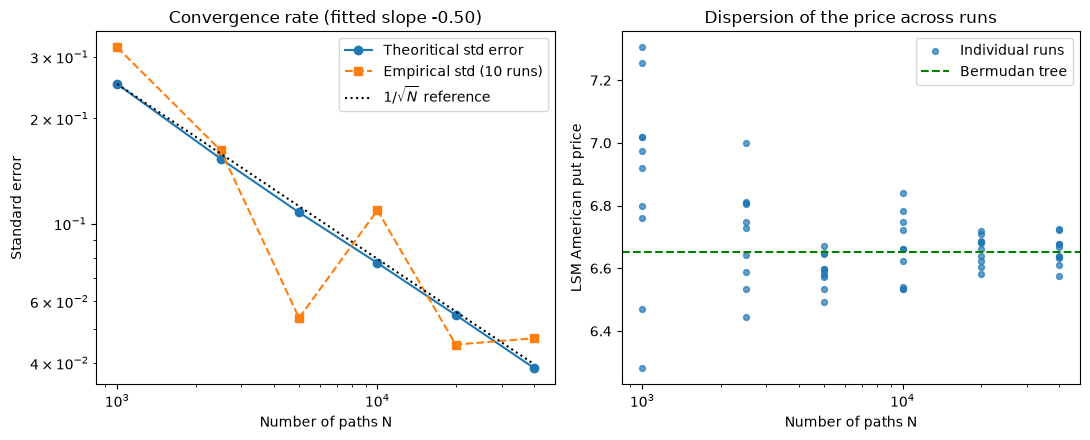

In [11]:
fig, ax = plt.subplots(1, 2, figsize=(11, 4.5))

Ns = summary["N"].values
ax[0].loglog(Ns, summary["mean_se"], "o-", label="Theoritical std error")
ax[0].loglog(Ns, summary["emp_std"], "s--", label="Empirical std (10 runs)")
ax[0].loglog(Ns, summary["mean_se"].iloc[0] * np.sqrt(Ns[0] / Ns), "k:", label=r"$1/\sqrt{N}$ reference")
ax[0].set_xlabel("Number of paths N")
ax[0].set_ylabel("Standard error")
ax[0].set_title(f"Convergence rate (fitted slope {slope_se:.2f})")
ax[0].legend()

ax[1].scatter(study["N"], study["price"], s=18, alpha=0.7, label="Individual runs")
ax[1].axhline(ref, color="green", linestyle="--", label="Bermudan tree")
ax[1].set_xscale("log")
ax[1].set_xlabel("Number of paths N")
ax[1].set_ylabel("LSM American put price")
ax[1].set_title("Dispersion of the price across runs")
ax[1].legend()

plt.tight_layout()
plt.savefig("../figures/ci_convergence.png", dpi=150)
plt.show()
